In [5]:
from pathlib import Path

import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt

In [6]:
BASE_DIR = Path(
    r"C:\Users\admin\Desktop\HWU\ResearchMethods\MachineLearningCVE"
)

DATA_FILE = BASE_DIR / "processed" / "cicids2017_clean.csv"
MODEL_FILE = BASE_DIR / "processed" / "random_forest_pilot.joblib"

data = pd.read_csv(DATA_FILE)
rf = joblib.load(MODEL_FILE)

print("Dataset:", data.shape)
print("Model loaded.")

Dataset: (2520798, 80)
Model loaded.


In [7]:
feature_columns = [
    col for col in data.columns
    if col not in ["Label", "BinaryLabel", "SourceFile"]
]

print("Number of features:", len(feature_columns))

Number of features: 77


In [8]:
attack_data = data[data["BinaryLabel"] == 1].sample(
    n=20_000,
    random_state=42
)

X_attack = attack_data[feature_columns]

baseline_pred = rf.predict(X_attack)

baseline_detected = baseline_pred == 1

print("Attack sample:", len(X_attack))
print("Correctly detected before perturbation:",
      baseline_detected.sum())
print("Baseline detection rate:",
      baseline_detected.mean())

Attack sample: 20000
Correctly detected before perturbation: 19889
Baseline detection rate: 0.99445


In [9]:
X_detected = X_attack.loc[baseline_detected].copy()

print("Flows used for evasion test:",
      len(X_detected))

Flows used for evasion test: 19889


In [10]:
def apply_timing_perturbation(X_input, factor):
    X_mod = X_input.copy()

    timing_features = [
        "Flow Duration",
        "Flow IAT Mean",
        "Flow IAT Std",
        "Flow IAT Max",
        "Flow IAT Min",

        "Fwd IAT Total",
        "Fwd IAT Mean",
        "Fwd IAT Std",
        "Fwd IAT Max",
        "Fwd IAT Min",

        "Bwd IAT Total",
        "Bwd IAT Mean",
        "Bwd IAT Std",
        "Bwd IAT Max",
        "Bwd IAT Min"
    ]

    rate_features = [
        "Flow Bytes/s",
        "Flow Packets/s",
        "Fwd Packets/s",
        "Bwd Packets/s"
    ]

    for feature in timing_features:
        if feature in X_mod.columns:
            X_mod[feature] = X_mod[feature] * factor

    for feature in rate_features:
        if feature in X_mod.columns:
            X_mod[feature] = X_mod[feature] / factor

    return X_mod

In [11]:
factors = [1.00, 1.05, 1.10, 1.20, 1.30]

results = []

for factor in factors:

    X_modified = apply_timing_perturbation(
        X_detected,
        factor
    )

    predictions = rf.predict(X_modified)

    detection_rate = (predictions == 1).mean()
    evasion_rate = (predictions == 0).mean()

    results.append({
        "TimingFactor": factor,
        "DetectionRate": detection_rate,
        "EvasionRate": evasion_rate
    })

results_df = pd.DataFrame(results)

results_df

,TimingFactor,DetectionRate,EvasionRate
0,1.00,1.000000,0.000000
1,1.05,0.995425,0.004575
2,1.10,0.992961,0.007039
3,1.20,0.990698,0.009302
4,1.30,0.990196,0.009804


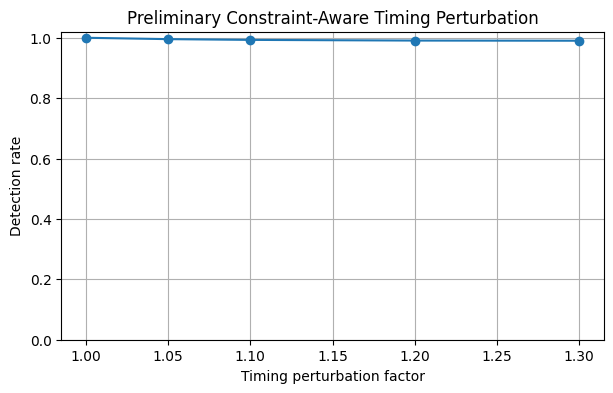

In [12]:
plt.figure(figsize=(7, 4))

plt.plot(
    results_df["TimingFactor"],
    results_df["DetectionRate"],
    marker="o"
)

plt.xlabel("Timing perturbation factor")
plt.ylabel("Detection rate")
plt.title("Preliminary Constraint-Aware Timing Perturbation")

plt.ylim(0, 1.02)
plt.grid(True)

plt.show()